# Exercice 1 — Régression : prédiction du salaire

**Objectif :** construire un modèle de régression linéaire multiple avec PyTorch pour prédire le salaire mensuel à partir de :
- l'ancienneté (années) ;
- le niveau d'expertise (1 à 5).

La règle de génération utilisée dans l'énoncé est approximativement :

**Salaire = 4000 + 600 × Ancienneté + 1500 × Expertise + Bruit**

Les données sont fictives et les salaires sont exprimés en DH.

## 1. Générer les données

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Bruit aléatoire
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Variables d'entrée et sortie
X = torch.cat([anciennete, expertise], dim=1)
y = salaires

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Salaire moyen :", y.mean().item(), "DH")

print("\nQuelques exemples :")
for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.5537109375 DH

Quelques exemples :
Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


## 2. Visualiser les données

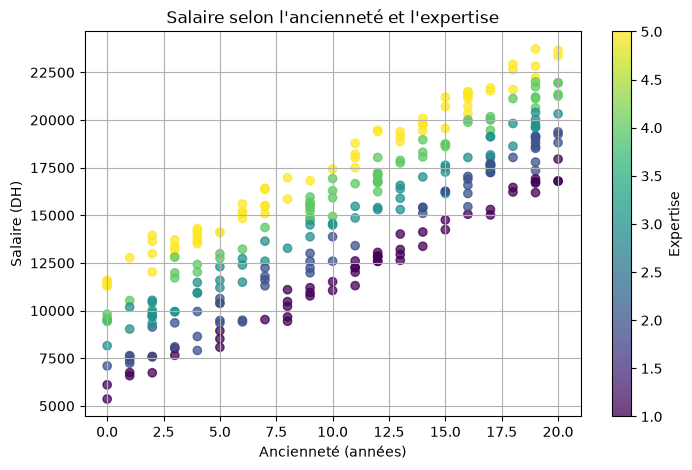

In [2]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X[:, 0].numpy(),
    y[:, 0].numpy(),
    c=X[:, 1].numpy(),
    cmap="viridis",
    alpha=0.75
)

plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire (DH)")
plt.title("Salaire selon l'ancienneté et l'expertise")
plt.colorbar(scatter, label="Expertise")
plt.grid()
plt.show()

## 3. Séparer et préparer les données

On utilise **80 % pour l'entraînement** et **20 % pour le test**.

Les salaires sont exprimés en milliers de DH et les variables d'entrée sont standardisées à partir des statistiques du jeu d'entraînement.

In [3]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

# Salaires en milliers de DH
y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur l'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : torch.Size([240, 2])
X_test  : torch.Size([60, 2])
y_train : torch.Size([240, 1])
y_test  : torch.Size([60, 1])


## 4. Construire et entraîner le modèle

In [4]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

# Optimiseur SGD
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


## 5. Tracer l'évolution de la perte

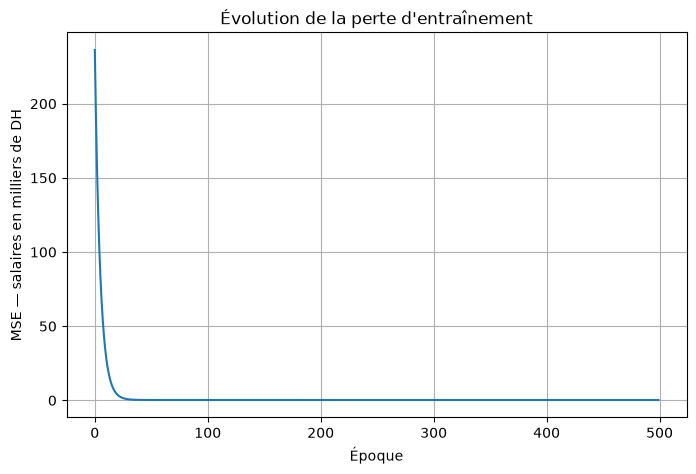

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

## 6. Évaluer les prédictions avec la MAE

In [6]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # MAE
    mae = torch.mean(
        torch.abs(predictions_dh - salaires_reels_dh)
    )

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


### Interprétation

La **MAE (Mean Absolute Error)** mesure l'écart absolu moyen entre les salaires prédits et les salaires réels.

Par exemple, une MAE de 400 DH signifie que les prédictions s'écartent en moyenne de 400 DH des salaires réels.

## 7. Prédire le salaire d'un nouveau salarié

In [7]:
# Nouveau salarié :
# 7 ans d'ancienneté et expertise 4/5
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (
    nouveau_salarie - moyenne
) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")

# Valeur théorique sans bruit
salaire_theorique = 4000 + 600 * 7 + 1500 * 4
print(f"Salaire théorique sans bruit : {salaire_theorique:.2f} DH")

Salaire estimé : 14201.94 DH
Salaire théorique sans bruit : 14200.00 DH


## 8. Retrouver les coefficients dans les unités d'origine

Le modèle a été entraîné sur des entrées standardisées et un salaire exprimé en milliers de DH.

On reconvertit donc les coefficients vers les unités d'origine.

Pour un modèle :

`y_norm = w_norm · X_norm + b_norm`

les coefficients d'origine sont :

`coefficient_original = w_norm × 1000 / ecart_type`

et l'interception d'origine est :

`b_original = (b_norm - Σ(w_norm × moyenne / ecart_type)) × 1000`.

In [8]:
with torch.no_grad():
    poids_norm = model.weight[0]
    biais_norm = model.bias[0]

    coefficients_dh = poids_norm * 1000 / ecart_type[0]

    biais_dh = (
        biais_norm
        - torch.sum(poids_norm * moyenne[0] / ecart_type[0])
    ) * 1000

print(f"Coefficient ancienneté : {coefficients_dh[0].item():.2f} DH/an")
print(f"Coefficient expertise   : {coefficients_dh[1].item():.2f} DH/niveau")
print(f"Interception            : {biais_dh.item():.2f} DH")

Coefficient ancienneté : 592.66 DH/an
Coefficient expertise   : 1490.75 DH/niveau
Interception            : 4090.30 DH


## 9. Questions complémentaires — réponses

### 1. À expertise constante, quel est l'effet d'une année d'ancienneté supplémentaire ?

Une année supplémentaire d'ancienneté augmente le salaire d'environ **600 DH**, selon la règle utilisée pour générer les données.

### 2. Pourquoi la perte ne devient-elle pas exactement nulle ?

Parce que le salaire contient un **bruit aléatoire**. Les deux variables utilisées par le modèle ne permettent donc pas d'expliquer toutes les variations individuelles.

### 3. Le modèle est-il fiable pour une ancienneté de 40 ans ?

Pas nécessairement. Les données d'entraînement contiennent des anciennetés comprises entre **0 et 20 ans**. Une prédiction à 40 ans serait une extrapolation en dehors de la plage observée.

### 4. Quel effet aurait une augmentation du bruit sur la précision ?

Une augmentation du bruit rendrait les salaires plus difficiles à prédire et devrait généralement augmenter l'erreur de prédiction.

### 5. Quels coefficients doit-on retrouver ?

Ils devraient être proches de :

- **600 DH** pour une année d'ancienneté ;
- **1500 DH** pour un niveau d'expertise ;
- **4000 DH** pour l'interception.

### Remarque

Traiter l'expertise comme une variable numérique suppose que le passage d'un niveau au suivant a le même effet sur le salaire. C'est une simplification pédagogique.

## Conclusion

Le modèle apprend une relation linéaire entre l'ancienneté, l'expertise et le salaire. La performance est évaluée sur un jeu de test à l'aide de la MAE, puis le modèle est utilisé pour prédire le salaire d'un nouveau salarié.